# Experimentos com regularização entrópica na tomografia quântica

O objetivo deste notebook é estudar, com exemplos pequenos, como o parâmetro de regularização
\(\epsilon\) e o algoritmo de otimização afetam a reconstrução.

**Arquivos originais:** `entropyreg.py` e `quantum_tomography.py`. As funções desses arquivos
não são modificadas. As únicas funções novas estão nas células de apoio abaixo e servem para
organizar os experimentos.

## Ordem dos experimentos

1. Comparar Gradient Descent e atualização estocástica por coordenadas em um estado de dois qubits.
2. Escolher uma faixa razoável de learning rates para o método estocástico.
3. Mostrar o que a regularização faz quando as medidas são incompletas.
4. Variar \(\epsilon\) em um exemplo no qual ele realmente altera o estado selecionado.
5. Comparar a convergência para diferentes classes de estados.
6. Opcionalmente, visualizar os estados usando uma representação de Wigner para spins no QuTiP.

Começamos com valores esperados exatos (sem shot noise). Assim, isolamos o comportamento do
otimizador e da regularização antes de acrescentar ruído experimental.

## 0. Imports e convenções

A convenção para as observáveis de dois qubits é a string de Pauli: por exemplo, `"ZI"` representa
\(\sigma_z\otimes I\). A identidade `"II"` é incluída nas medições para impor
\(\operatorname{Tr}(\rho)=1\).

O código abaixo aceita tanto os nomes normais dos módulos (`entropyreg.py`, `quantum_tomography.py`)
quanto os nomes que os arquivos receberam ao serem anexados a uma conversa (`entropyreg(1).py`,
`quantum_tomography(1).py`).

In [1]:
import os
import sys
import time
import importlib.util
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

def carregar_modulo(nome, arquivos):
    for arquivo in arquivos:
        if os.path.exists(arquivo):
            spec = importlib.util.spec_from_file_location(nome, arquivo)
            modulo = importlib.util.module_from_spec(spec)
            sys.modules[nome] = modulo
            spec.loader.exec_module(modulo)
            return modulo
    raise FileNotFoundError(f"Não encontrei nenhum destes arquivos: {arquivos}")

qt = carregar_modulo(
    "quantum_tomography",
    ["quantum_tomography.py", "quantum_tomography(1).py", "/mnt/data/quantum_tomography(1).py"]
)
er = carregar_modulo(
    "entropyreg",
    ["entropyreg.py", "entropyreg(1).py", "/mnt/data/entropyreg(1).py"]
)

np.set_printoptions(precision=5, suppress=True)

## 1. Funções auxiliares para análise

As funções abaixo **não alteram** `entropyreg.py`. Elas apenas:
- reconstroem a exponencial dual e normalizam a matriz para calcular métricas;
- calculam a entropia de von Neumann e geram um estado de Gibbs;
- organizam as observáveis de Pauli e registram a norma do **gradiente completo** no teste estocástico.

Na comparação entre algoritmos, o método estocástico continua atualizando apenas \(k\) coordenadas
por iteração. A norma usada para avaliar a convergência, porém, será sempre
\(\|\nabla g(u)\|_2\), calculada com todas as observáveis.

In [2]:
def rho_a_partir_de_u(u, H, Q_list, epsilon):
    operador = sum(u_i * Q_i for u_i, Q_i in zip(u, Q_list)) - H
    return expm(operador / epsilon)


def normalizar_rho(rho):
    tr = np.trace(rho).real
    if not np.isfinite(tr) or tr <= 0:
        raise ValueError("A exponencial não produziu um traço positivo e finito.")
    return rho / tr


def entropia_von_neumann(rho):
    rho_h = (rho + rho.conj().T) / 2
    autovalores = np.linalg.eigvalsh(rho_h)
    autovalores = np.clip(autovalores, 0.0, None)
    positivos = autovalores[autovalores > 1e-14]
    return float(-np.sum(positivos * np.log(positivos)))


def estado_gibbs(H, beta):
    """Estado térmico exp(-beta H)/Z. Função auxiliar deste notebook."""
    return qt.QuantState(normalizar_rho(expm(-beta * H)))


def montar_observaveis_pauli(n_qubits):
    nomes = ["I" * n_qubits] + qt.pauli_basis_strings(n_qubits)
    matrizes = [qt.pauli_string_to_matrix(nome) for nome in nomes]
    return nomes, matrizes


def rodar_estocastico_com_historico(H, Q_list, q, epsilon, k, lr,
                                    max_iters=5000, tol=1e-6, seed=0,
                                    check_every=10):
    """
    Atualiza k coordenadas sorteadas. A cada check_every passos, calcula
    a norma do gradiente completo para avaliar/parar o método.
    """
    rng = np.random.default_rng(seed)
    u = np.zeros(len(q), dtype=float)
    m = len(q)
    historico = [[0, np.linalg.norm(er.dual_gradient(u, H, Q_list, q, epsilon))]]
    inicio = time.perf_counter()

    for t in range(1, max_iters + 1):
        grad_parcial, _ = er.stochastic_gradient(
            u, H, Q_list, q, epsilon, rng=rng, k=k
        )
        if not np.all(np.isfinite(grad_parcial)):
            break
        u -= lr * grad_parcial

        if t % check_every == 0:
            # k=m faz stochastic_gradient devolver todas as componentes:
            # portanto, aqui temos o gradiente completo.
            grad_completo, _ = er.stochastic_gradient(
                u, H, Q_list, q, epsilon, rng=rng, k=m
            )
            norma = np.linalg.norm(grad_completo)
            historico.append([t, norma])
            if np.isfinite(norma) and norma < tol:
                break

    tempo = time.perf_counter() - inicio
    return u, t, np.asarray(historico), tempo

## 2. Comparação inicial: Gradient Descent vs. método estocástico

Usaremos um estado misto de posto completo em dois qubits e todas as 16 observáveis de Pauli
(incluindo a identidade). Esse caso permite comparar os algoritmos em um problema bem determinado,
sem a dificuldade adicional de tentar reconstruir um estado puro na fronteira do conjunto de
matrizes positivas.

A curva do método estocástico não será a norma do gradiente parcial sorteado: será a norma do
gradiente completo, calculada a cada 10 iterações. Assim, as duas curvas medem a mesma quantidade.

In [3]:
n_qubits = 2
estado_alvo = qt.random_mixture_of_pures(dim=2**n_qubits, rank=4, seed=17)

nomes_obs, Q = montar_observaveis_pauli(n_qubits)
q = qt.measure_observables(estado_alvo, nomes_obs)

H = np.zeros((2**n_qubits, 2**n_qubits), dtype=complex)
epsilon = 1.0

print(estado_alvo)
print("Número de observáveis:", len(Q))
print("Traço do estado-alvo:", np.trace(estado_alvo.rho).real)
print("Autovalores do estado-alvo:", np.linalg.eigvalsh(estado_alvo.rho))

<QuantState (2 qubits, Misto (posto 4), pureza=0.306)>
Número de observáveis: 16
Traço do estado-alvo: 1.0
Autovalores do estado-alvo: [0.13135 0.19604 0.22764 0.44497]


In [4]:
lr_comparacao = 0.75
tol = 1e-6
check_every = 10
max_iters = 5000

# Gradient Descent completo
t0 = time.perf_counter()
gd_data = er.gradient_descent(
    H, Q, q, epsilon, max_iters=max_iters, lr=lr_comparacao, tol=tol
)
tempo_gd = time.perf_counter() - t0
u_gd, it_gd, us_gd, grad_gd = gd_data

# Método estocástico com k coordenadas por iteração
t0 = time.perf_counter()
u_st, it_st, hist_st = er.sgd(
    H, Q, q, epsilon, k=len(Q)//2, lr=lr_comparacao,
    n_iter=max_iters, tol=tol, seed=0,
    check_every=check_every, count_it=check_every
)
tempo_st = time.perf_counter() - t0

rho_gd = normalizar_rho(rho_a_partir_de_u(u_gd, H, Q, epsilon))
rho_st = normalizar_rho(rho_a_partir_de_u(u_st, H, Q, epsilon))

print("Gradient Descent")
print("iterações:", it_gd, "| tempo (s):", round(tempo_gd, 4))
print("norma final do gradiente:", np.linalg.norm(er.dual_gradient(u_gd, H, Q, q, epsilon)))
print("fidelidade:", qt.fidelidade(rho_gd, estado_alvo.rho))

print("\nMétodo estocástico")
print("iterações:", it_st, "| tempo (s):", round(tempo_st, 4))
print("norma final do gradiente:", np.linalg.norm(er.dual_gradient(u_st, H, Q, q, epsilon)))
print("fidelidade:", qt.fidelidade(rho_st, estado_alvo.rho))

Gradient Descent
iterações: 26 | tempo (s): 0.0036
norma final do gradiente: 8.895819275333286e-07
fidelidade: 0.9999999999996745

Método estocástico
iterações: 60 | tempo (s): 0.0035
norma final do gradiente: 5.59865478905908e-07
fidelidade: 0.9999999999998932


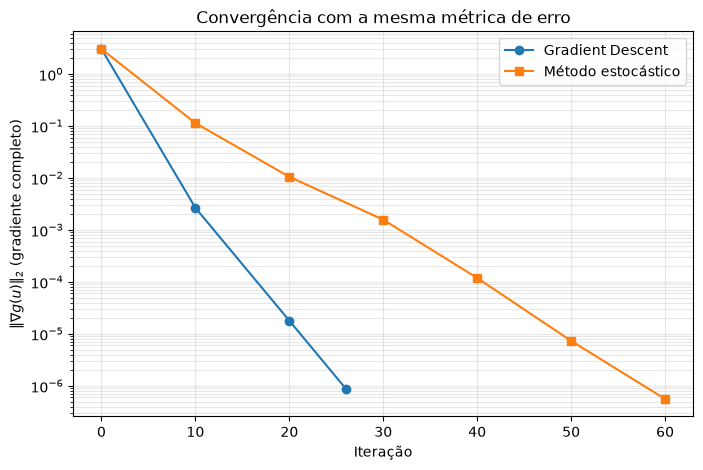

In [5]:
# O GD registra todos os passos; selecionamos os mesmos instantes usados no SGD.
hist_gd = np.asarray(grad_gd)
hist_gd = hist_gd[hist_gd[:, 0] % check_every == 0]
grad_gd_final = np.linalg.norm(er.dual_gradient(u_gd, H, Q, q, epsilon))
if hist_gd[-1, 0] != it_gd:
    hist_gd = np.vstack([hist_gd, [it_gd, grad_gd_final]])

hist_st = np.asarray(hist_st)
grad_inicial = np.linalg.norm(
    er.dual_gradient(np.zeros(len(q)), H, Q, q, epsilon)
)
hist_st = np.vstack([[0, grad_inicial], hist_st])

plt.figure(figsize=(8, 5))
plt.semilogy(hist_gd[:, 0], hist_gd[:, 1], "o-", label="Gradient Descent")
plt.semilogy(hist_st[:, 0], hist_st[:, 1], "s-", label="Método estocástico")
plt.xlabel("Iteração")
plt.ylabel(r"$\|\nabla g(u)\|_2$ (gradiente completo)")
plt.title("Convergência com a mesma métrica de erro")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

**Como interpretar:** neste exemplo, os dois métodos têm o mesmo alvo e a mesma métrica de
convergência. O estocástico deve ser avaliado pelo número de iterações e pelo tempo, mas não se
deve concluir que ele sempre será mais rápido: a exponencial matricial ainda é calculada em cada
iteração. Na implementação atual, a economia de memória mais clara é que `sgd` não armazena toda a
trajetória de vetores \(u_k\), enquanto `gradient_descent` guarda essa trajetória em `us`.
A comparação de tempo deve ser repetida com mais de uma semente para ser conclusiva.

## 3. Variação do learning rate

A partir daqui usamos o método estocástico. Para não escolher um valor com base em uma única
execução, testamos cada learning rate com algumas sementes. Registramos:
- fração das execuções que atingiu a tolerância;
- número médio de iterações **entre as execuções que convergiram**;
- tempo médio.

Uma execução que chega ao limite `max_iters` sem atingir a tolerância não deve ser contada como
convergida.

In [6]:
lr_values = [0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0]
seeds = range(5)
max_iters_lr = 3000
tol_lr = 1e-6
k = len(Q) // 2

taxas_convergencia = []
iteracoes_medias = []
tempos_medios = []

for lr in lr_values:
    it_ok = []
    tempos = []
    for seed in seeds:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            t0 = time.perf_counter()
            u, n_it, _ = er.sgd(
                H, Q, q, epsilon, k=k, lr=lr,
                n_iter=max_iters_lr, tol=tol_lr,
                seed=seed, check_every=10, count_it=0
            )
            tempos.append(time.perf_counter() - t0)

        grad_final = er.dual_gradient(u, H, Q, q, epsilon)
        if np.all(np.isfinite(grad_final)) and np.linalg.norm(grad_final) < tol_lr:
            it_ok.append(n_it)

    taxas_convergencia.append(len(it_ok) / len(list(seeds)))
    iteracoes_medias.append(np.mean(it_ok) if it_ok else np.nan)
    tempos_medios.append(np.mean(tempos))

for lr, taxa, its, tempo in zip(lr_values, taxas_convergencia,
                                 iteracoes_medias, tempos_medios):
    print(f"lr={lr:>4}: convergência={taxa:.0%}, "
          f"iterações médias={its:.1f}, tempo médio={tempo:.4f}s")

lr=0.25: convergência=100%, iterações médias=188.0, tempo médio=0.0079s
lr= 0.5: convergência=100%, iterações médias=88.0, tempo médio=0.0036s
lr=0.75: convergência=100%, iterações médias=64.0, tempo médio=0.0026s
lr= 1.0: convergência=100%, iterações médias=54.0, tempo médio=0.0023s
lr=1.25: convergência=100%, iterações médias=54.0, tempo médio=0.0023s
lr= 1.5: convergência=100%, iterações médias=84.0, tempo médio=0.0035s
lr=1.75: convergência=100%, iterações médias=236.0, tempo médio=0.0097s
lr= 2.0: convergência=0%, iterações médias=nan, tempo médio=0.1211s


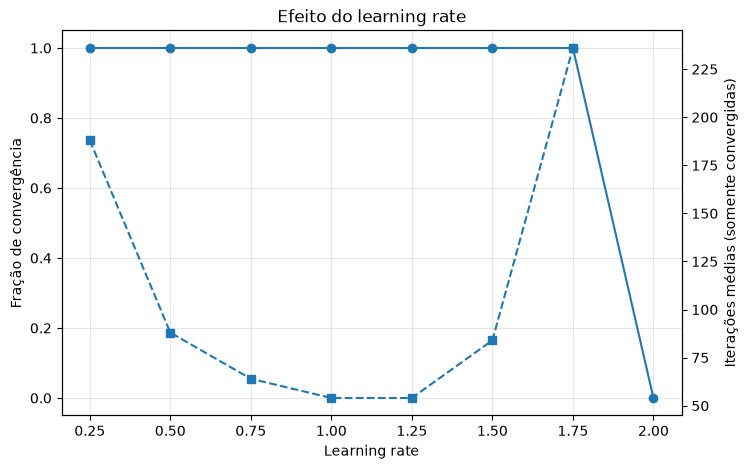

In [7]:
fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(lr_values, taxas_convergencia, "o-", label="Fração que convergiu")
ax1.set_xlabel("Learning rate")
ax1.set_ylabel("Fração de convergência")
ax1.set_ylim(-0.05, 1.05)
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(lr_values, iteracoes_medias, "s--", label="Iterações médias")
ax2.set_ylabel("Iterações médias (somente convergidas)")
plt.title("Efeito do learning rate")
plt.show()

**Escolha prática:** use como valor de referência um learning rate que tenha convergência em
todas ou quase todas as sementes e baixo número médio de iterações. Evite escolher o maior valor
que funcionou em uma execução: perto da região instável, pequenas mudanças na semente podem fazer
o método divergir. A faixa encontrada é específica para este estado, \(\epsilon\), \(k\) e conjunto
de observáveis; ela não é uma fórmula universal.

## 4. Medidas incompletas: não unicidade física e solução regularizada única

Agora consideramos o estado de Bell
\[
|\Phi^+\rangle = \frac{|00\rangle+|11\rangle}{\sqrt{2}},
\]
mas medimos apenas \(I\otimes I\), \(Z\otimes I\) e \(I\otimes Z\). Essas medidas não revelam
a coerência entre \(|00\rangle\) e \(|11\rangle\).

De fato, toda a família
\[
|\psi_\phi\rangle =
\frac{|00\rangle+e^{i\phi}|11\rangle}{\sqrt{2}}
\]
produz os mesmos três valores esperados. O estado maximamente misto também é compatível com
esses mesmos dados. Portanto, o estado verdadeiro não é identificado pelas medidas.

In [8]:
I4 = qt.pauli_string_to_matrix("II")
ZI = qt.pauli_string_to_matrix("ZI")
IZ = qt.pauli_string_to_matrix("IZ")
Q_incompleto = [I4, ZI, IZ]

bell = qt.standard_pure_state("bell", n_qubits=2)
q_incompleto = qt.measure_observables(bell, ["II", "ZI", "IZ"])

def estado_fase(phi):
    vetor = np.array([1, 0, 0, np.exp(1j * phi)], dtype=complex) / np.sqrt(2)
    return qt.QuantState(vetor)

estados_compativeis = [
    estado_fase(0),
    estado_fase(np.pi/2),
    estado_fase(np.pi),
    qt.maximally_mixed_state(4)
]

for i, estado in enumerate(estados_compativeis):
    medidas = qt.measure_observables(estado, ["II", "ZI", "IZ"])
    print(i, medidas)

print("Dados-alvo:", q_incompleto)

0 [1. 0. 0.]
1 [1. 0. 0.]
2 [1. 0. 0.]
3 [1. 0. 0.]
Dados-alvo: [1. 0. 0.]


Com \(H=0\), a regularização entrópica seleciona o estado de maior entropia dentro do conjunto
compatível com as medidas: neste exemplo, a matriz maximamente mista \(I/4\).
Esse é um único minimizador do problema regularizado, mas **não é uma descoberta do estado de Bell**.
A coerência e o emaranhamento não estão contidos nos dados medidos.

In [9]:
H_zero_2 = np.zeros((4, 4), dtype=complex)

resultado_incompleto = er.reconstruct_spi(
    H_zero_2, Q_incompleto, q_incompleto,
    epsilon=1.0, max_iters=5000, lr=0.5,
    tol=1e-7, k=2, seed=0, count_it=0
)

rho_incompleto = normalizar_rho(resultado_incompleto[0])

print("Iterações:", resultado_incompleto[2])
print("Traço:", np.trace(rho_incompleto).real)
print("Autovalores:", np.linalg.eigvalsh(rho_incompleto))
print("Medidas reconstruídas:",
      [np.trace(rho_incompleto @ Q_i).real for Q_i in Q_incompleto])
print("Fidelidade com Bell:", qt.fidelidade(rho_incompleto, bell.rho))
print("Fidelidade com I/4:",
      qt.fidelidade(rho_incompleto, qt.maximally_mixed_state(4).rho))

Iterações: 50
Traço: 1.0
Autovalores: [0.25 0.25 0.25 0.25]
Medidas reconstruídas: [np.float64(1.0), np.float64(0.0), np.float64(0.0)]
Fidelidade com Bell: 0.2499999999999999
Fidelidade com I/4: 1.0


**Mensagem para a apresentação:** a regularização remove a ambiguidade do critério de otimização
ao escolher um único estado ótimo, mas não torna informativamente completa uma coleção incompleta
de medidas. A solução depende também do Hamiltoniano \(H\) e de \(\epsilon\). Para \(H=0\),
o critério seleciona a solução de máxima entropia. Essa distinção é fundamental para não afirmar
que o método recupera univocamente o estado físico desconhecido.

## 5. Efeito de \(\epsilon\): um exemplo em que ele altera o estado selecionado

No teste anterior, \(H=0\). Nesse caso, \(\epsilon>0\) apenas multiplica a entropia no problema
primal: o minimizador físico não muda quando variamos \(\epsilon\). Portanto, aquele teste é útil
para estudar a convergência numérica, mas não para visualizar a competição física entre energia
e entropia.

Agora mantemos as mesmas medidas incompletas e escolhemos
\[
H=-J(Z\otimes Z),\qquad J=0.2.
\]
Como \(H\) comuta com as observáveis medidas, o estado de Gibbs
\[
\rho_\epsilon =
\frac{e^{-H/\epsilon}}{\operatorname{Tr}(e^{-H/\epsilon})}
\]
é uma solução analítica deste exemplo. Ao diminuir \(\epsilon\), a energia ganha peso relativo;
ao aumentar \(\epsilon\), a entropia favorece o estado maximamente misto.

In [10]:
J = 0.2
H_epsilon = -J * qt.pauli_string_to_matrix("ZZ")
epsilon_values = [0.25, 0.5, 1.0, 2.0, 4.0]

resultados_epsilon = {}

for eps in epsilon_values:
    # Esta escolha de lr é empírica para manter uma escala de passo comparável
    # neste exemplo; não é uma regra universal.
    lr_eps = 0.3 * eps

    resultado = er.reconstruct_spi(
        H_epsilon, Q_incompleto, q_incompleto,
        epsilon=eps, max_iters=10000, lr=lr_eps,
        tol=1e-7, k=2, seed=0, count_it=0
    )
    rho = normalizar_rho(resultado[0])
    rho_gibbs = normalizar_rho(expm(-H_epsilon / eps))

    resultados_epsilon[eps] = {
        "rho": rho,
        "iteracoes": resultado[2],
        "gradiente": np.linalg.norm(
            er.dual_gradient(resultado[1], H_epsilon, Q_incompleto,
                             q_incompleto, eps)
        ),
        "energia": np.trace(rho @ H_epsilon).real,
        "entropia": entropia_von_neumann(rho),
        "fidelidade_gibbs": qt.fidelidade(rho, rho_gibbs)
    }

for eps in epsilon_values:
    r = resultados_epsilon[eps]
    print(f"eps={eps:>4}: it={r['iteracoes']:>4}, "
          f"||grad||={r['gradiente']:.2e}, "
          f"E={r['energia']:.6f}, S={r['entropia']:.6f}, "
          f"F(Gibbs)={r['fidelidade_gibbs']:.6f}")

eps=0.25: it= 100, ||grad||=1.71e-11, E=-0.132807, S=1.145819, F(Gibbs)=1.000000
eps= 0.5: it= 100, ||grad||=2.01e-11, E=-0.075990, S=1.312268, F(Gibbs)=1.000000
eps= 1.0: it= 100, ||grad||=2.05e-11, E=-0.039475, S=1.366687, F(Gibbs)=1.000000
eps= 2.0: it= 100, ||grad||=2.06e-11, E=-0.019934, S=1.381319, F(Gibbs)=1.000000
eps= 4.0: it= 100, ||grad||=2.06e-11, E=-0.009992, S=1.385046, F(Gibbs)=1.000000


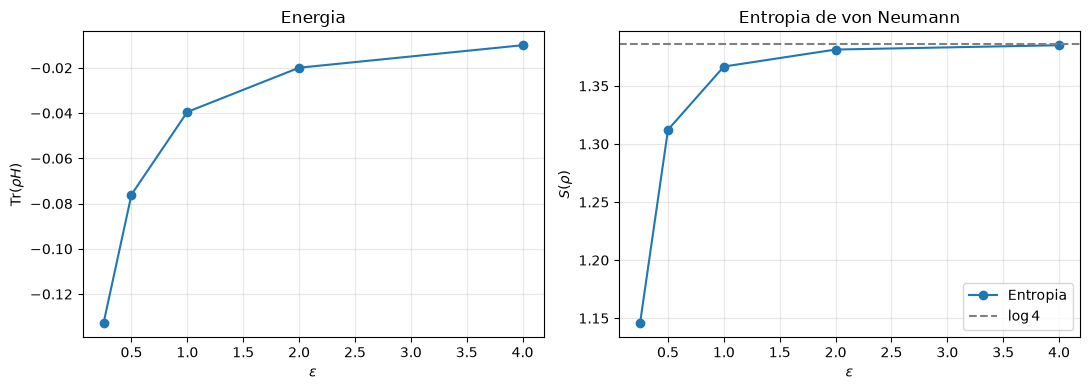

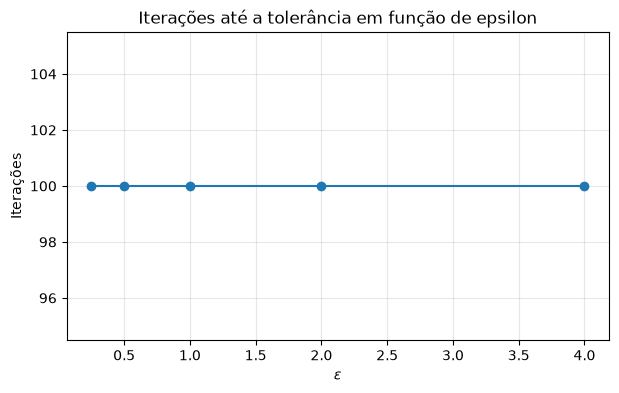

In [11]:
energias = [resultados_epsilon[e]["energia"] for e in epsilon_values]
entropias = [resultados_epsilon[e]["entropia"] for e in epsilon_values]
iteracoes = [resultados_epsilon[e]["iteracoes"] for e in epsilon_values]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(epsilon_values, energias, "o-")
ax[0].set_xlabel(r"$\epsilon$")
ax[0].set_ylabel(r"$\operatorname{Tr}(\rho H)$")
ax[0].set_title("Energia")
ax[0].grid(True, alpha=0.3)

ax[1].plot(epsilon_values, entropias, "o-", label="Entropia")
ax[1].axhline(np.log(4), color="gray", ls="--", label=r"$\log 4$")
ax[1].set_xlabel(r"$\epsilon$")
ax[1].set_ylabel(r"$S(\rho)$")
ax[1].set_title("Entropia de von Neumann")
ax[1].grid(True, alpha=0.3)
ax[1].legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(epsilon_values, iteracoes, "o-")
plt.xlabel(r"$\epsilon$")
plt.ylabel("Iterações")
plt.title("Iterações até a tolerância em função de epsilon")
plt.grid(True, alpha=0.3)
plt.show()

## 6. Convergência para diferentes classes de estados

Agora usamos medidas completas de Pauli em dois qubits e comparamos:
1. um estado puro (Bell);
2. uma mistura de dois estados puros;
3. um estado misto de posto completo, construído ao misturar Bell com \(I/4\);
4. um estado de Gibbs de um Hamiltoniano simples.

Para estados de posto completo, a solução dual pode ser atingida com um vetor \(u\) finito. Para
estados puros ou misturas de posto menor que a dimensão, a matriz-alvo tem autovalores nulos.
Como uma exponencial matricial finita é estritamente positiva, o algoritmo pode se aproximar da
solução na fronteira sem atingir exatamente o alvo em um número finito de iterações. Assim,
pode ocorrer de a fidelidade já ser muito alta mesmo quando a norma do gradiente ainda não atingiu
a tolerância.

In [12]:
I4 = np.eye(4, dtype=complex)
estado_puro = qt.standard_pure_state("bell", n_qubits=2)
estado_mistura_puros = qt.random_mixture_of_pures(4, rank=2, seed=23)
estado_misto = qt.QuantState(0.65 * estado_puro.rho + 0.35 * I4 / 4)

H_fisico = (
    -0.8 * qt.pauli_string_to_matrix("ZZ")
    -0.3 * qt.pauli_string_to_matrix("XI")
    -0.3 * qt.pauli_string_to_matrix("IX")
)
estado_termico = estado_gibbs(H_fisico, beta=0.8)

estados = {
    "Puro (Bell)": estado_puro,
    "Mistura de puros (posto 2)": estado_mistura_puros,
    "Misto (posto 4)": estado_misto,
    "Gibbs": estado_termico
}

for nome, estado in estados.items():
    print(nome, "| pureza =", round(estado.purity, 5),
          "| posto =", estado.rank)

Puro (Bell) | pureza = 1.0 | posto = 1
Mistura de puros (posto 2) | pureza = 0.76913 | posto = 2
Misto (posto 4) | pureza = 0.56687 | posto = 4
Gibbs | pureza = 0.34734 | posto = 4


In [13]:
epsilon_familias = 1.0
lr_familias = 0.8
k_familias = len(Q) // 2
max_iters_familias = 8000
tol_familias = 1e-4
resultados_familias = {}

for nome, estado in estados.items():
    q_estado = qt.measure_observables(estado, nomes_obs)

    u, n_it, historico, tempo = rodar_estocastico_com_historico(
        H, Q, q_estado, epsilon_familias, k=k_familias,
        lr=lr_familias, max_iters=max_iters_familias,
        tol=tol_familias, seed=0, check_every=20
    )
    rho = normalizar_rho(rho_a_partir_de_u(u, H, Q, epsilon_familias))
    grad_final = np.linalg.norm(
        er.dual_gradient(u, H, Q, q_estado, epsilon_familias)
    )

    resultados_familias[nome] = {
        "rho": rho,
        "historico": historico,
        "iteracoes": n_it,
        "gradiente": grad_final,
        "fidelidade": qt.fidelidade(rho, estado.rho),
        "tempo": tempo,
        "convergiu": grad_final < tol_familias
    }

for nome, r in resultados_familias.items():
    print(f"{nome:28} | convergiu={r['convergiu']} | "
          f"it={r['iteracoes']:>5} | ||grad||={r['gradiente']:.2e} | "
          f"F={r['fidelidade']:.6f} | tempo={r['tempo']:.3f}s")

Puro (Bell)                  | convergiu=False | it= 8000 | ||grad||=2.96e-04 | F=0.999771 | tempo=0.322s
Mistura de puros (posto 2)   | convergiu=False | it= 8000 | ||grad||=2.68e-04 | F=0.999846 | tempo=0.322s
Misto (posto 4)              | convergiu=True | it=   60 | ||grad||=7.87e-05 | F=1.000000 | tempo=0.002s
Gibbs                        | convergiu=True | it=   60 | ||grad||=6.93e-06 | F=1.000000 | tempo=0.002s


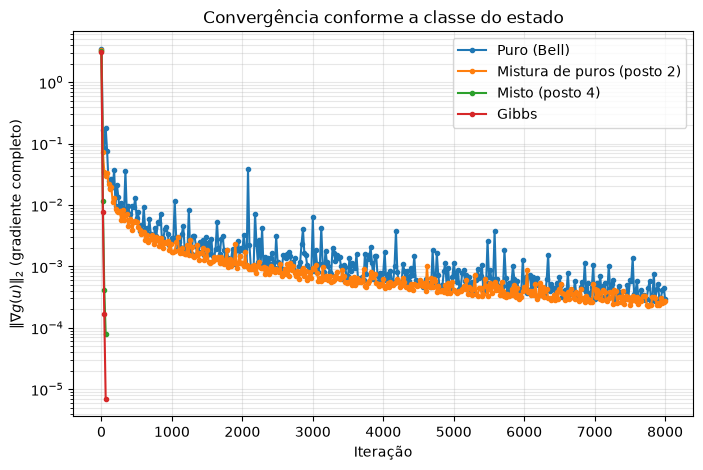

In [14]:
plt.figure(figsize=(8, 5))
for nome, r in resultados_familias.items():
    h = r["historico"]
    plt.semilogy(h[:, 0], h[:, 1], "o-", markersize=3, label=nome)

plt.xlabel("Iteração")
plt.ylabel(r"$\|\nabla g(u)\|_2$ (gradiente completo)")
plt.title("Convergência conforme a classe do estado")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

## 7. Visualização com QuTiP: Wigner e Weyl

A função de Wigner é uma representação de um estado por uma função sobre um espaço de fase.
Para sistemas contínuos, como o oscilador harmônico, o espaço costuma ser descrito por duas
coordenadas (posição e momento). A função não é uma probabilidade clássica comum: pode assumir
valores negativos.

Para qubits, não usamos diretamente a versão contínua \(W(x,p)\) como se o qubit fosse um
oscilador. A representação mais apropriada é uma **função de Wigner de spin**, definida na esfera.
Para vários qubits, pode-se usar a transformação de Wigner discreta/finita do QuTiP, que constrói
uma representação angular para cada subsistema. Uma fatia bidimensional é uma visualização útil,
mas não contém, isoladamente, todos os graus de liberdade de um sistema multipartido.

A ideia de Weyl aparece na função característica
\[
\chi(\xi)=\operatorname{Tr}[\rho D(\xi)],
\qquad
D(\xi)=e^{\xi a^\dagger-\xi^*a},
\]
e a função de Wigner está relacionada a ela por uma transformada de Fourier. Em outras palavras,
Wigner/Weyl muda a representação matemática do estado; não é um segundo estado nem um algoritmo
de reconstrução alternativo.

**O que eu sugiro para a apresentação:** use um exemplo de um qubit para explicar visualmente a
representação na esfera de Bloch (que seu módulo já sabe desenhar). Como extensão, mostre a
representação de Wigner de spin do estado Bell e do estado regularizado. Isso pode ilustrar quais
características das correlações não foram fixadas pelas medidas incompletas. Não precisa tornar
essa visualização o centro do trabalho.

/tmp/ipykernel_13328/1268220806.py:71: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


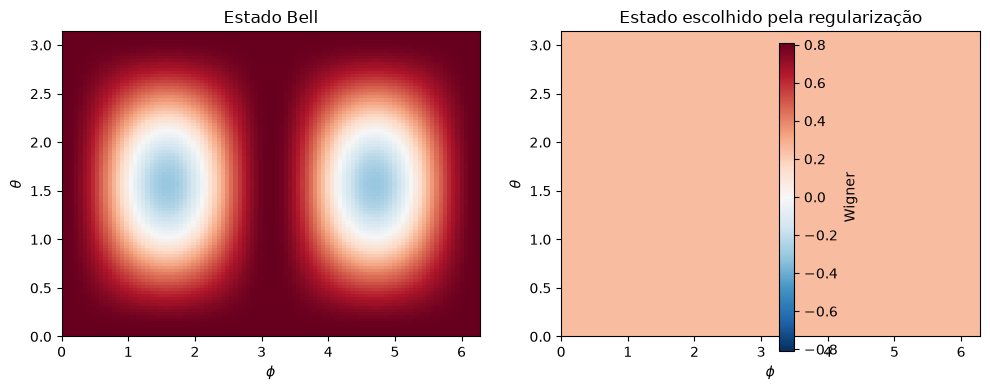

In [16]:
# Célula opcional: requer QuTiP 5.x.
# Caso não esteja instalado no ambiente: %pip install qutip

try:
    import qutip as qtp
    from qutip.wigner import wigner_transform

    def wigner_dois_qubits(rho, steps=100):

        # Garantimos que rho seja hermitiana
        rho = np.asarray(rho, dtype=complex)
        rho = (rho + rho.conj().T) / 2

        # Decomposição espectral
        valores, vetores = np.linalg.eigh(rho)

        # Pequenas correções numéricas
        valores = np.clip(valores, 0, None)
        valores = valores / np.sum(valores)

        # Inicializamos a função de Wigner
        W = np.zeros((steps, steps))

        for valor, vetor in zip(valores, vetores.T):

            if valor > 1e-12:

                # Construímos um ket de dois qubits
                psi = qtp.Qobj(
                    vetor.reshape(4, 1),
                    dims=[[2, 2], [1, 1]]
                )

                # Calculamos a contribuição do estado puro
                W_puro = wigner_transform(
                    psi,
                    j=0.5,
                    fullparity=True,
                    steps=steps,
                    slicearray=["l", "l"]
                )

                # Somamos com o peso correspondente
                W += valor * W_puro

        return W

    W_bell = wigner_dois_qubits(bell.rho)
    W_reg = wigner_dois_qubits(rho_incompleto)

    vmax = max(np.max(np.abs(W_bell)), np.max(np.abs(W_reg)))
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))

    im0 = ax[0].imshow(
        W_bell, origin="lower", extent=[0, 2*np.pi, 0, np.pi],
        aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax
    )
    ax[0].set_title("Estado Bell")
    ax[0].set_xlabel(r"$\phi$")
    ax[0].set_ylabel(r"$\theta$")

    im1 = ax[1].imshow(
        W_reg, origin="lower", extent=[0, 2*np.pi, 0, np.pi],
        aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax
    )
    ax[1].set_title("Estado escolhido pela regularização")
    ax[1].set_xlabel(r"$\phi$")
    ax[1].set_ylabel(r"$\theta$")

    fig.colorbar(im1, ax=ax, label="Wigner")
    plt.tight_layout()
    plt.show()

except ImportError:
    print("QuTiP não está instalado. Execute %pip install qutip e rode esta célula novamente.")

## 8. Sequência sugerida para a apresentação

1. **Validação do método:** dois qubits, medidas completas, estado misto de posto completo; comparar GD e estocástico usando a norma do gradiente completo.
2. **Escolha numérica:** variar learning rate e justificar o valor adotado nas próximas experiências.
3. **O que a regularização resolve:** medidas incompletas; exibir os vários estados compatíveis e a solução única selecionada pelo critério entrópico. Ressaltar que ela não recupera informação que não foi medida.
4. **Papel físico de epsilon:** usar \(H\ne0\) para mostrar a competição entre energia e entropia.
5. **Dependência do tipo de estado:** comparar puros, misturas, mistos e Gibbs, discutindo a dificuldade adicional dos estados de posto deficiente.
6. **Visualização opcional:** Bloch para um qubit e, se o tempo permitir, Wigner de spin para dois qubits.

Os testes acima usam dados ideais. Depois dessa sequência, um teste com `N_shots` finito pode ser acrescentado para avaliar o efeito do ruído estatístico. Nesse caso, é importante lembrar que igualdades exatas com dados ruidosos podem não admitir uma matriz densidade que satisfaça todas as restrições simultaneamente; pode ser necessário formular uma versão aproximada/regularizada do ajuste.